# Pure Bending of a Cantilever Beam

Validation example for the geometrically nonlinear beam element
(`src/flexsim/formulations/jirasek.py`), based on:

> Jirasek, M., La Malfa Ribolla, E., Horak, M. "Efficient finite difference
> formulation of a geometrically nonlinear beam element." *International
> Journal for Numerical Methods in Engineering*, 122(23):7013-7053, 2021.
> Section 4.1. See `derivations/references.md`.

A cantilever of length `L` and bending stiffness `EI`, fixed at one end,
loaded at the free end by a pure moment `M`, bends into a circular arc of
radius `R = EI / M` -- exact for arbitrarily large rotation, not just small
deflections. This makes it a clean check on the element's large-rotation
behavior with a genuinely closed-form answer to compare against (no
approximation, no reference finite-element solution needed).

This notebook: define the geometry -> render it -> apply the moment
incrementally -> render the deformed shapes at each load step -> compare the
final tip position/rotation against the exact circular-arc solution.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parents[1] / "src"))

import numpy as np
import matplotlib.pyplot as plt

from flexsim.formulations.jirasek import JirasekBeam, n_segments_from_thickness
from flexsim.frame import Frame

## Define geometry

Single beam, length `L`, rectangular cross-section (`width` x `thickness`),
fixed at the left end (node A). The number of finite-difference integration
segments is chosen from the section thickness (`n_segments_from_thickness`,
`design/architecture.md`): one segment per two thickness-widths of arc
length is enough here -- see the segment-count convergence check near the
end of this notebook for why.

In [2]:
L = 1.0
E = 1.0
width = 1.0
thickness = 0.01  # L/thickness = 100, a genuinely slender beam

n_seg = n_segments_from_thickness(L, thickness, spacing_factor=2.0)
print(f"n_seg = {n_seg}")

beam = JirasekBeam(xa0=0.0, za0=0.0, xb0=L, zb0=0.0,
                    E=E, width=width, thickness=thickness, n_seg=n_seg)

frame = Frame()
node_A = frame.add_node(0.0, 0.0)
node_B = frame.add_node(L, 0.0)
frame.add_element(node_A, node_B, beam)

# Cantilever support: node A fully fixed.
frame.fix(node_A, 0, 0.0)
frame.fix(node_A, 1, 0.0)
frame.fix(node_A, 2, 0.0)

n_seg = 50


## Render initial geometry

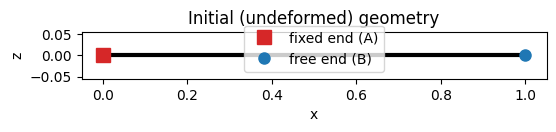

In [3]:
fig, ax = plt.subplots(figsize=(6, 2))
ax.plot([beam.xa0, beam.xb0], [beam.za0, beam.zb0], "k-", lw=3)
ax.plot(beam.xa0, beam.za0, "s", color="tab:red", markersize=10, label="fixed end (A)")
ax.plot(beam.xb0, beam.zb0, "o", color="tab:blue", markersize=8, label="free end (B)")
ax.set_aspect("equal")
ax.set_xlabel("x"); ax.set_ylabel("z")
ax.set_title("Initial (undeformed) geometry")
ax.legend()
plt.show()

## Apply loading and solve

Pure moment at the free end (node B), zero applied force there, ramped
incrementally from zero up to `M = theta * EI / L` for a target tip rotation
`theta` (here a quarter turn, 90 degrees -- matches the paper's Figure 3
setup, which goes further, to a full closed loop, over six load steps).

`Frame.solve` doubles the number of load increments automatically if a given
increment fails to converge (see `src/flexsim/frame.py`); starting directly
with a fine step count here just avoids the wasted early attempts. See
`design/roadmap.md` for the performance note on making this properly
adaptive instead of restart-based.

In [4]:
EI = beam.EI
theta_target = np.pi / 2  # quarter circle
M_target = theta_target * EI / L

frame.load(node_B, 0, 0.0)
frame.load(node_B, 1, 0.0)
frame.load(node_B, 2, M_target)

history = frame.solve(n_steps=3000, tol=1e-6, max_newton=15, verbose=False, max_step_doublings=1)
print(f"solved in {len(history)} load steps")

solved in 3000 load steps


## Deformed shapes at each load step

Plotted directly from the shooting method's own integration grid points
(`Beam.deformed_shape_global`) -- no separate shape-function interpolation
needed, per the "integration points double as plotting points" idea this
notebook is meant to demonstrate.

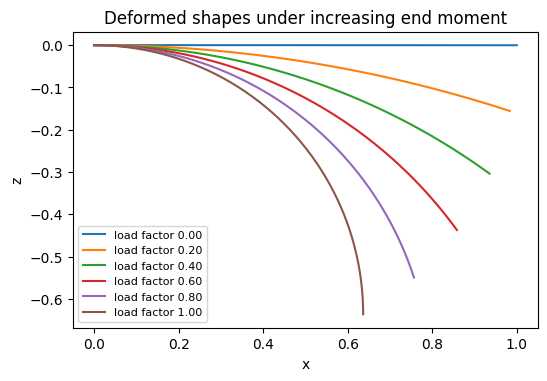

In [5]:
fig, ax = plt.subplots(figsize=(6, 6))
snap_fractions = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
snap_indices = [int(f * (len(history) - 1)) for f in snap_fractions]

for idx in snap_indices:
    step = history[idx]
    dofA, dofB = step.u[0:3], step.u[3:6]
    result = beam.compute(dofA, dofB)
    shape = beam.deformed_shape_global(dofA, result)
    ax.plot(shape[:, 0], shape[:, 1], label=f"load factor {step.load_factor:.2f}")

ax.set_aspect("equal")
ax.set_xlabel("x"); ax.set_ylabel("z")
ax.set_title("Deformed shapes under increasing end moment")
ax.legend(fontsize=8)
plt.show()

## Compare to the analytical circular-arc solution

For pure end-moment loading, the left-end axial/shear force components
(`X_ab`, `Z_ab`) are exactly zero and the curvature `kappa = phi'` is
constant along the beam, giving a closed-form tip position:

```
u_tip = sin(kappa*L)/kappa - L
w_tip = (cos(kappa*L) - 1)/kappa
phi_tip = kappa*L
```

with `kappa = theta_target / L` (see `derivations/beam_stiffness_euler_bernoulli.md`-
adjacent notes; this result doesn't depend on which beam formulation is used,
it's just the kinematics of constant curvature).

In [6]:
kappa = theta_target / L
u_exact = np.sin(kappa * L) / kappa - L
w_exact = (np.cos(kappa * L) - 1) / kappa
phi_exact = theta_target

u_computed = history[-1].u[3:6]
exact = np.array([u_exact, w_exact, phi_exact])
error = np.abs(u_computed - exact)

print("computed tip [u, w, phi]:", u_computed)
print("exact tip    [u, w, phi]:", exact)
print("absolute error:          ", error)

computed tip [u, w, phi]: [-0.36335405 -0.63664595  1.57079633]
exact tip    [u, w, phi]: [-0.36338023 -0.63661977  1.57079633]
absolute error:           [2.61806927e-05 2.61806923e-05 5.92637051e-13]


## Segment-count convergence check

Per Jirasek et al. (2021), Table 1: accuracy is controlled by the number of
finite-difference integration segments `n_seg`, not by adding more global
elements -- error should drop roughly with the square of the segment
spacing. Quick check here using tip-rotation error as a scalar convergence
metric.

In [7]:
results = []
for n_seg_test in [5, 10, 20, 40, 80]:
    beam_test = JirasekBeam(xa0=0.0, za0=0.0, xb0=L, zb0=0.0,
                             E=E, width=width, thickness=thickness, n_seg=n_seg_test)
    frame_test = Frame()
    a = frame_test.add_node(0.0, 0.0)
    b = frame_test.add_node(L, 0.0)
    frame_test.add_element(a, b, beam_test)
    frame_test.fix(a, 0, 0.0); frame_test.fix(a, 1, 0.0); frame_test.fix(a, 2, 0.0)
    frame_test.load(b, 0, 0.0); frame_test.load(b, 1, 0.0); frame_test.load(b, 2, M_target)
    hist_test = frame_test.solve(n_steps=3000, tol=1e-6, max_newton=15, max_step_doublings=1)
    u_test = hist_test[-1].u[3:6]
    err = np.linalg.norm(u_test - exact)
    results.append((n_seg_test, err))
    print(f"n_seg={n_seg_test:4d}   |error| = {err:.3e}")

n_seg=   5   |error| = 3.713e-03
n_seg=  10   |error| = 9.263e-04
n_seg=  20   |error| = 2.314e-04
n_seg=  40   |error| = 5.785e-05
n_seg=  80   |error| = 1.446e-05
